# SARGen: an automated, explainable SAR ADC generator in SKY130

**IEEE SSCS Code-a-Chip - ISSCC 2027**

| Name | Affiliation | Contact | IEEE member | SSCS member |
|---|---|---|---|---|
| Rajinthan Rameshkumar | Final-year undergraduate, Dept. of Electronic and Telecommunication Engineering, University of Moratuwa, Sri Lanka | rajinthan519@gmail.com, [rajinthan.com](https://rajinthan.com) | Yes | No |

## Abstract
Successive-approximation (SAR) ADCs are the workhorse of low-power data conversion, yet the path from a
specification ("I need N bits at f<sub>s</sub>") to sized transistors is usually hidden in a designer's head.
**SARGen** turns that path into a reproducible, open-source workflow. The user enters the resolution
(4 to 8 bits) and the sample rate; the notebook then

1. **explains** the charge-redistribution binary search with an animation,
2. **characterizes the SKY130 PDK** with ngspice (Pelgrom A<sub>VT</sub>, switch R<sub>on</sub>, MIM density and matching),
3. **sizes every block** from those numbers - unit capacitor (matching vs. kT/C), StrongARM comparator (offset),
   sampling switches and DAC drivers (settling) - and logs *why* each size was chosen,
4. **generates the transistor-level netlist** (MIM CDAC, transmission gates, StrongARM, XSPICE SAR logic),
5. **verifies** it at transistor level: ramp/histogram INL-DNL, coherent-FFT ENOB, comparator-offset Monte Carlo,
   power and Walden FoM, plus a PDK-calibrated behavioral Monte Carlo for yield.

The first target is a complete **4-bit** flow; the same code scales to 8 bits. Automated layout (gLayout)
and post-layout (PEX) re-simulation are the next stages of the flow (see *Roadmap*).

## How to run
Everything uses open-source tools inside the **IIC-OSIC-TOOLS** container (tested with tag `2026.10`:
ngspice-47, Magic, Netgen, KLayout, SKY130A).

```bash
docker run -it --rm -p 127.0.0.1:8888:8888 -v $PWD:/foss/designs hpretl/iic-osic-tools:2026.10 -s jupyter lab
```
or, headless: `python3 run_flow.py --bits 4`. Python dependencies: numpy, matplotlib, pillow (all in the image).
A complete 4-bit run takes a few minutes on a laptop (simulations run in parallel).

## 1. Specification
Change `BITS` (4..8) and `FS` and re-run the notebook - every number below is regenerated.

In [1]:
import json, os
from pathlib import Path
from IPython.display import Image, Markdown, display

from sargen import SarSpec
from sargen.flow import run_flow
from sargen.model import SarModel
from sargen.anim import animate_conversion
from sargen.sizing import sizing_table_md

BITS = 4          # resolution (4..8)
FS = 10e6         # sample rate [S/s]
spec = SarSpec(bits=BITS, fs=FS)
OUT = Path(f"build/{BITS}bit")
print(json.dumps(spec.to_dict(), indent=1))

{
 "bits": 4,
 "fs": 10000000.0,
 "vdd": 1.8,
 "vref": 1.8,
 "temp": 27.0,
 "corner": "tt",
 "dnl_3sigma_lsb": 0.25,
 "offset_3sigma_lsb": 0.5,
 "noise_lsb": 0.1,
 "settle_lsb": 0.25,
 "lsb": 0.1125,
 "vcm": 0.9,
 "cycles": 6,
 "fclk": 60000000.0
}


## 2. How a SAR ADC works - animated
The input is sampled on the bottom plates of a binary-weighted capacitor array while the top plate is held at
V<sub>cm</sub>. Afterwards the bottom plates are switched to V<sub>ref</sub> or ground one bit at a time
(MSB first). Charge conservation makes the top plate move by
$V_x - V_{cm} = \sum_i b_i\,\frac{C_i}{C_{tot}}V_{ref} - V_{in}$, so the comparator only has to decide the
*sign*: if the DAC voltage is still below V<sub>in</sub> the bit is kept, otherwise it is cleared.
After N decisions the bits are the binary code of V<sub>in</sub>.

```
            Vin ──┬── TG ──┐ bottom plates        top plate
                  │        ├── 2^(N-1)C ─┐
            Vref ─┼─ drv ──┤   ...       ├──────── Vx ──(+)\
            GND  ─┘        ├──   C   ────┤                    StrongARM ── SAR logic ── bits
                           └── C_dummy ──┘  Vcm ──TG── Vx     (-)/
                                                      Vcm ─────┘
```

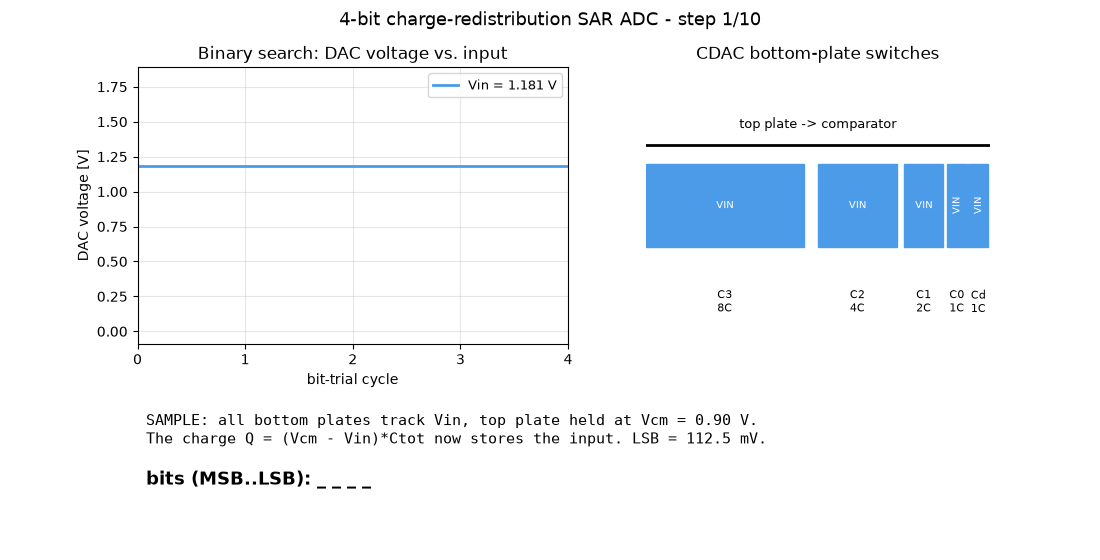

In [2]:
OUT.mkdir(parents=True, exist_ok=True)
vin_demo = round(0.6 * 2**BITS) * spec.lsb + 0.5 * spec.lsb
animate_conversion(SarModel(BITS, spec.vref), vin_demo, OUT / "sar_animation.gif")
Image(filename=str(OUT / "sar_animation.gif"))

## 3. Run the automated flow
`run_flow` executes all stages; each is explained in the following sections.
PDK characterization is cached in `build/char/` after the first run.

In [3]:
res = run_flow(spec, OUT)

[   0.0s] 1/8 PDK characterization (A_VT, R_on, MIM)
[   0.0s] 2/8 sizing
[   0.0s] 3/8 netlist + single-conversion transient


[  11.4s] 4/8 comparator offset Monte Carlo (24 x 8 instances)


[ 139.0s] 5/8 ramp test: 32 hits/code, transistor level


[ 288.2s] 6/8 sine test: 128-point coherent FFT, transistor level


[ 329.4s] 7/8 mismatch Monte Carlo: behavioral model x 1000 (+0 SPICE seeds)


[ 329.8s] 8/8 animation + report


[ 332.1s] done -> build/4bit


## 4. PDK characterization (ngspice, SKY130 `tt` / `tt_mm`)
No textbook constants are used. The flow measures:
* **A<sub>VT</sub>**: 200 mismatch instances per geometry of diode-connected nfet/pfet in one netlist; A<sub>VT</sub> = sqrt(2) sigma(V<sub>GS</sub>) sqrt(WL).
* **R<sub>on</sub> x W** of a transmission gate (worst case over the input range) and of the NMOS/PMOS DAC drivers.
* **MIM capacitance** per area and per perimeter (AC simulation of three geometries), and the **MIM matching
  coefficient** read from the PDK model card (`sigma(dC/C) = 2.8 %/sqrt(WL)`).

In [4]:
c = res["char"]
display(Markdown(f'''
| quantity | value |
|---|---|
| A_VT nfet / pfet | {c["avt_n_mVum"]:.2f} / {c["avt_p_mVum"]:.2f} mV um |
| TG (Wn=1, Wp=2) worst R_on W | {c["ron_tg_ohm_um"]/1e3:.2f} kOhm um |
| NMOS / PMOS driver R_on W | {c["ron_n_ohm_um"]:.0f} / {c["ron_p_ohm_um"]:.0f} Ohm um |
| MIM density | {c["mim_ca_fF_um2"]:.3f} fF/um^2 + {c["mim_cp_fF_um"]:.3f} fF/um perimeter |
| MIM matching | {c["mim_match_pct_um"]} % um |
'''))


| quantity | value |
|---|---|
| A_VT nfet / pfet | 7.32 / 8.53 mV um |
| TG (Wn=1, Wp=2) worst R_on W | 12.11 kOhm um |
| NMOS / PMOS driver R_on W | 669 / 3095 Ohm um |
| MIM density | 2.000 fF/um^2 + 0.165 fF/um perimeter |
| MIM matching | 2.8 % um |


## 5. Specification-driven sizing
Each row is one design decision: the rule, the numbers that went in, and the result.

In [5]:
design = json.loads((OUT / "design.json").read_text())
display(Markdown(sizing_table_md(design)))

| block | rule | numbers | result |
|---|---|---|---|
| spec | LSB = Vref / 2^N | 1.8 V / 16 | **112.50 mV** |
| timing | Tclk = 1 / ((N + 2) * fs) | fs = 10 MS/s, 6 cycles | **16.67 ns (60.0 MHz)** |
| CDAC | sigma_DNL(mid-code) = sqrt(2^N - 1) * sigma_u <= DNL_3sigma / 3 | sigma_u <= 2.152 %, A_C = 2.8 %um | **side >= 1.30 um (matching)** |
| CDAC | kT/C: sqrt(kT / C_total) <= noise_lsb * LSB | C_total >= 0.0327 fF | **negligible at this resolution** |
| CDAC | Cu = Ca * s^2 + Cp * 4s (characterized MIM) | s = 2.00 um, limited by min. size | **Cu = 9.32 fF, C_total = 149.1 fF** |
| comparator | sigma_os ~ A_VT / sqrt(W L) <= offset_3sigma * LSB / 3 | A_VT = 7.32 mVum, target 18.75 mV | **W L >= 0.153 um^2 -> W/L = 2.0/0.3 (est. 9.45 mV)** |
| comparator | pre-amplifier needed if W L > 20 um^2 (input cap / kick-back) | W L = 0.15 um^2 | **no - StrongARM alone** |
| comparator | tail = 1.5 W_in, latch = W_in / 2, reset / inverters fixed |  | **tail 3.0, nlatch 1.0, platch 1.0 um** |
| sampling | tau = T_track / ln(2^N / settle_lsb); split between bit and top switch | T_track = 14.17 ns, tau <= 3406 ps | **R_unit <= 182.8 kOhm, R_top <= 11424 Ohm** |
| sampling | W_n = (R_on W)_TG,worst / R  (Wp = 2 Wn), bit-i switch = 2^i units | (R_on W) = 12.11 kOhm um | **unit TG 0.45/0.90 um, top TG 1.10/2.20 um** |
| DAC driver | tau = 0.45 Tclk / ln(2^N / settle_lsb), per unit cap (binary scaled) | tau <= 1803 ps, R_unit <= 96.8 kOhm | **unit NMOS 0.45 um, unit PMOS 0.45 um** |

## 6. Generated netlist and a single conversion
The testbench below is written by `sargen.netlist`. Watch the top plate: after sampling it starts at
V<sub>cm</sub>, jumps with every bit trial and converges back to V<sub>cm</sub> - the binary search in silicon.

* SAR ADC 4-bit testbench (generated by sargen)
.lib /foss/pdks/sky130A/libs.tech/ngspice/sky130.lib.spice tt
.temp 27.0
.option method=gear
.subckt strongarm inp inn clk qp qn vdd vss
XMt tail clk vss vss sky130_fd_pr__nfet_01v8 L=0.15 W=3 nf=1 ad=0.87 as=0.87 pd=6.58 ps=6.58 nrd=0.09667 nrs=0.09667 sa=0 sb=0 sd=0 mult=1 m=1
XMi1 xp inp tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMi2 xn inn tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMn1 outn outp xp vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMn2 outp outn xn vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMp1 outn outp vdd vdd sky130_fd_pr__pfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb

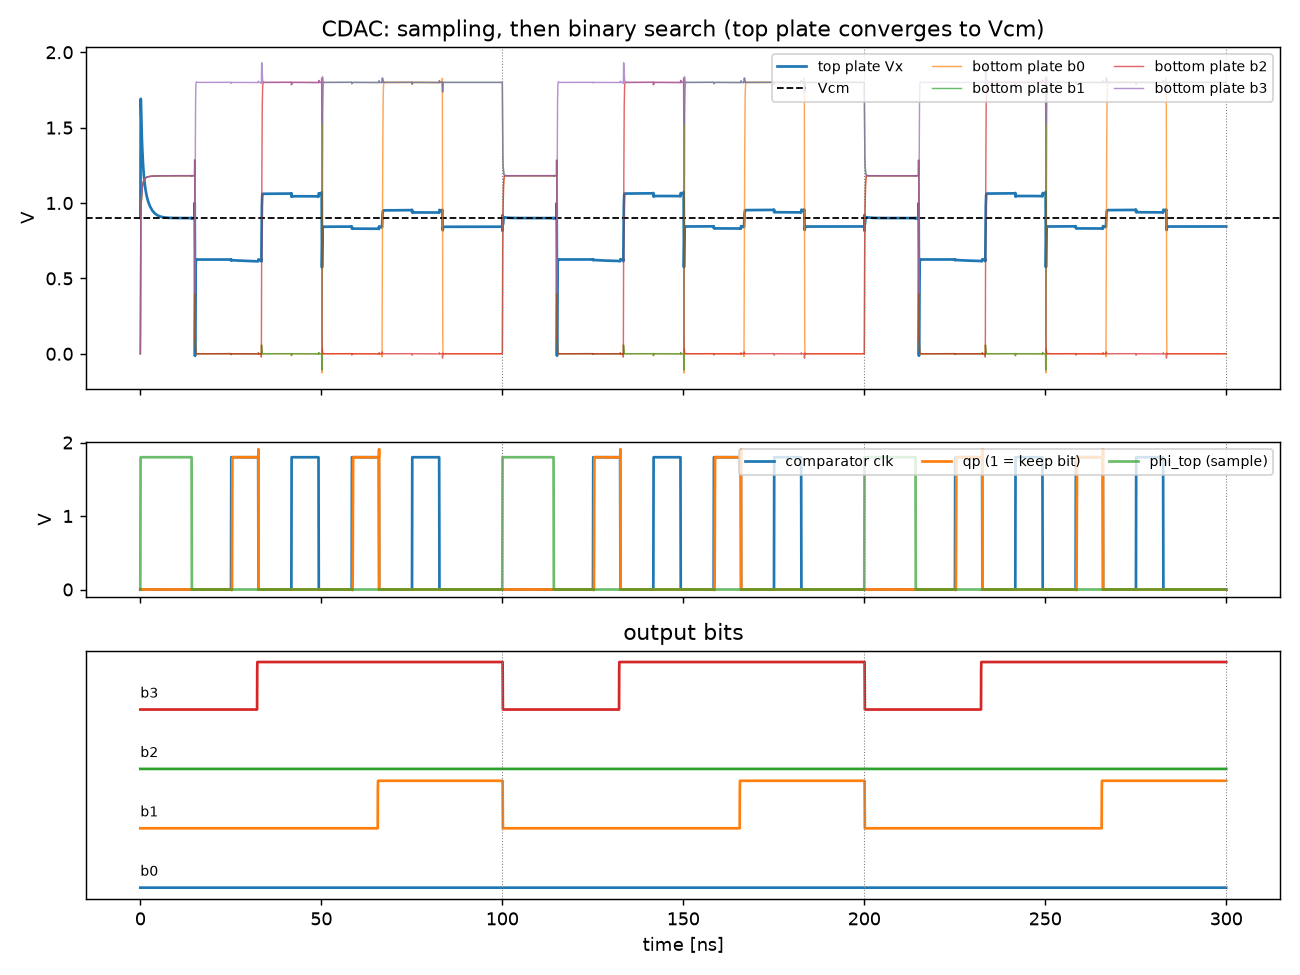

In [6]:
tb = (OUT / f"sar_adc_{BITS}b_tb.spice").read_text().splitlines()
print("\n".join(tb[:12] + ["..."] + [l for l in tb if l.startswith(("* ----", "abr", "aff"))][:20]))
print(f"\nVin = {res['single']['vin']:.4f} V -> code {res['single']['code']} (ideal {res['single']['ideal']})")
Image(filename=str(OUT / "waveforms.png"))

## 7. Comparator offset Monte Carlo
192 StrongARM instances with independent SKY130 mismatch are swept with a slow ramp. In this single-ended,
conventional-switching SAR the comparator offset only shifts the whole transfer curve (offset error); it does
not create DNL. That is why a small, fast comparator is enough at low resolution.

sigma_os = 8.00 mV  (0.071 LSB), mean = 1.22 mV, n = 192


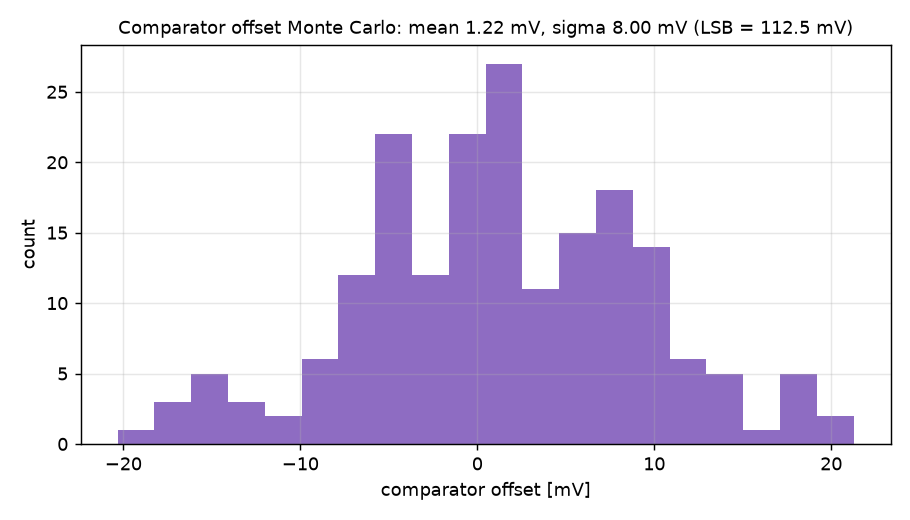

In [7]:
o = res["comparator_offset"]
print(f"sigma_os = {o['sigma']*1e3:.2f} mV  ({o['sigma']/spec.lsb:.3f} LSB), mean = {o['mean']*1e3:.2f} mV, n = {o['n']}")
Image(filename=str(OUT / "comparator_offset.png"))

## 8. Static linearity: ramp + code-density (histogram) test
A slow ramp that slightly over-drives both ends is applied to the transistor-level ADC. The number of hits per
code gives DNL; its running sum gives INL (end-point fit).

max|DNL| = 0.031 LSB, max|INL| = 0.021 LSB, missing codes = 0, offset = -0.089 LSB, gain error = -0.021 LSB


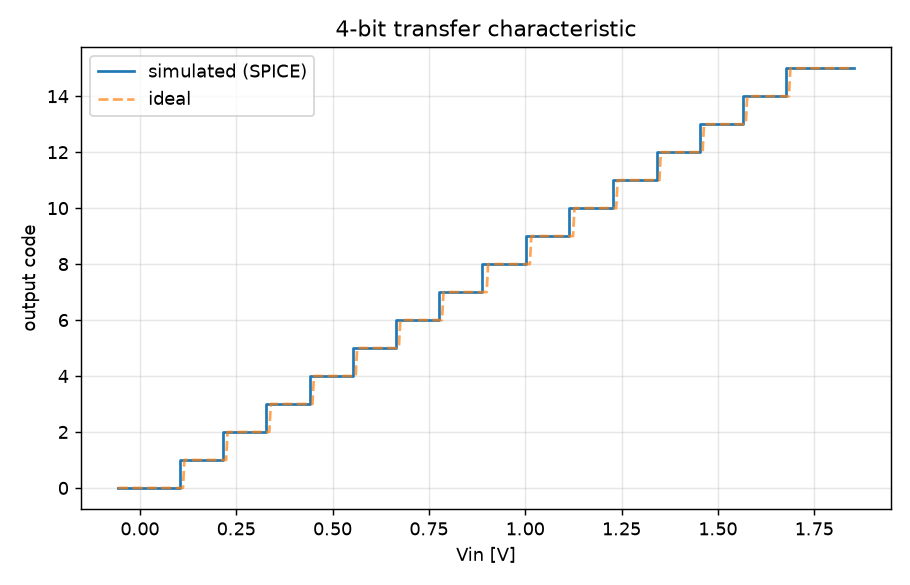

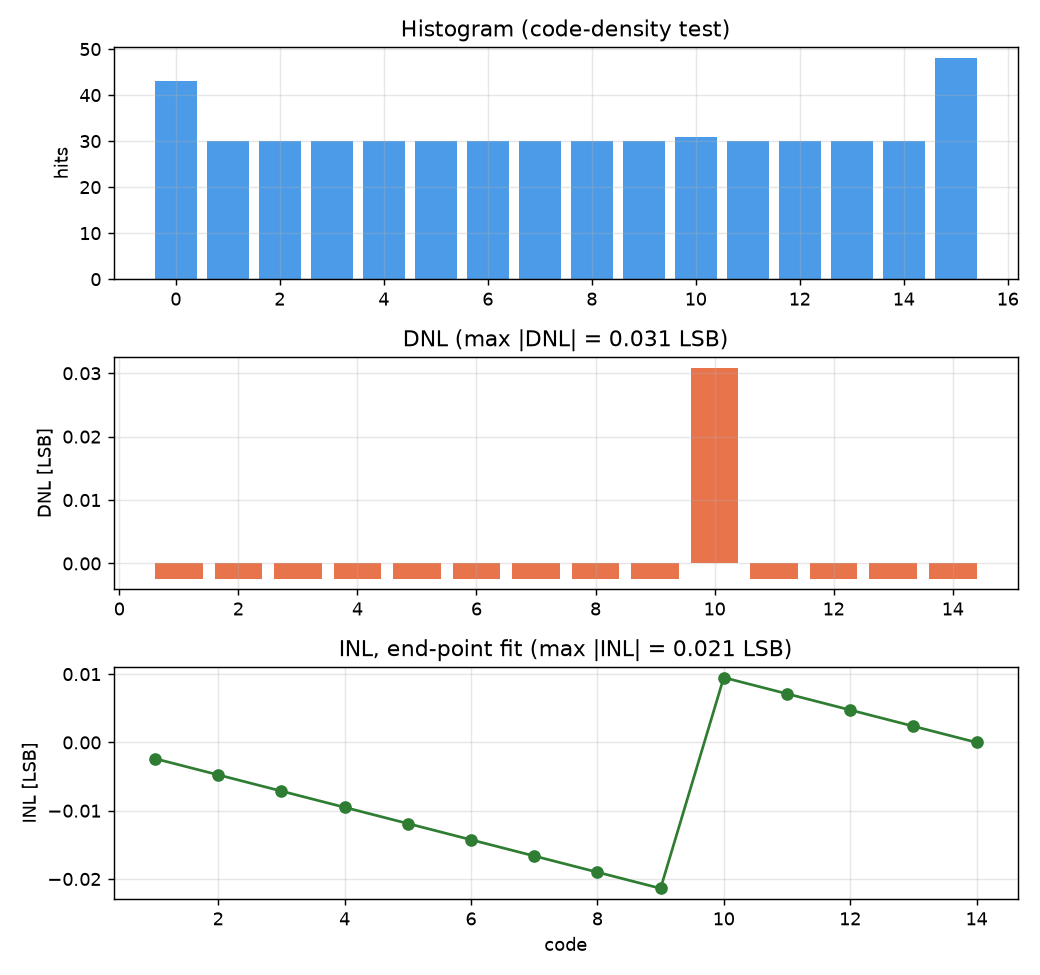

In [8]:
s = res["static"]
print(f"max|DNL| = {s['dnl_max']:.3f} LSB, max|INL| = {s['inl_max']:.3f} LSB, missing codes = {s['missing_codes']}, "
      f"offset = {s['offset_lsb']:.3f} LSB, gain error = {s['gain_error_lsb']:.3f} LSB")
display(Image(filename=str(OUT / "transfer.png")))
Image(filename=str(OUT / "inl_dnl_histogram.png"))

## 9. Dynamic performance: coherent FFT, ENOB
A full-scale sine with a prime number of cycles in the record (coherent sampling, no window) is converted at
transistor level. ENOB = (SNDR - 1.76 dB) / 6.02.

SNDR 25.72 dB, SFDR 35.9 dB, ENOB 3.98 bit (ideal 4-bit quantizer on the same samples: 3.97 bit)
Power 6.33 uW, 0.633 pJ/conv, Walden FoM 40.1 fJ/conv-step


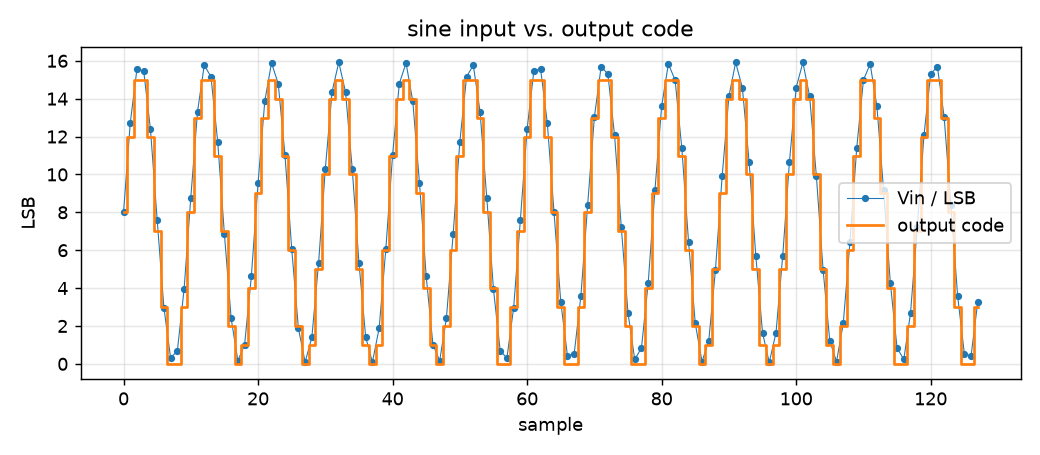

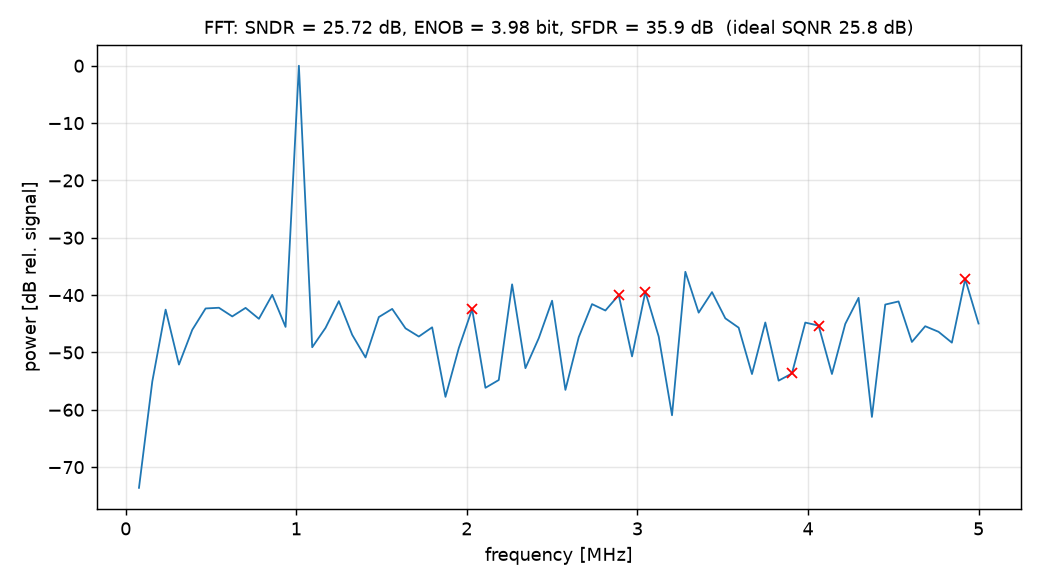

In [9]:
d, p = res["dynamic"], res["power"]
print(f"SNDR {d['sndr_db']:.2f} dB, SFDR {d['sfdr_db']:.1f} dB, ENOB {d['enob']:.2f} bit "
      f"(ideal {BITS}-bit quantizer on the same samples: {d['ideal_model_enob']:.2f} bit)")
print(f"Power {p['p_total']*1e6:.2f} uW, {p['energy_per_conv']*1e12:.3f} pJ/conv, Walden FoM {p['walden_fom_J']*1e15:.1f} fJ/conv-step")
display(Image(filename=str(OUT / "sine_samples.png")))
Image(filename=str(OUT / "fft.png"))

## 10. Yield: PDK-calibrated behavioral Monte Carlo
The behavioral model uses the *measured* unit-capacitor sigma (from the PDK MIM model) and comparator offset
sigma (section 7), so thousands of mismatch samples run in seconds.

1000 runs: 99th percentile DNL 0.130 LSB, INL 0.083 LSB, yield(DNL<0.5 LSB) = 100.0 %


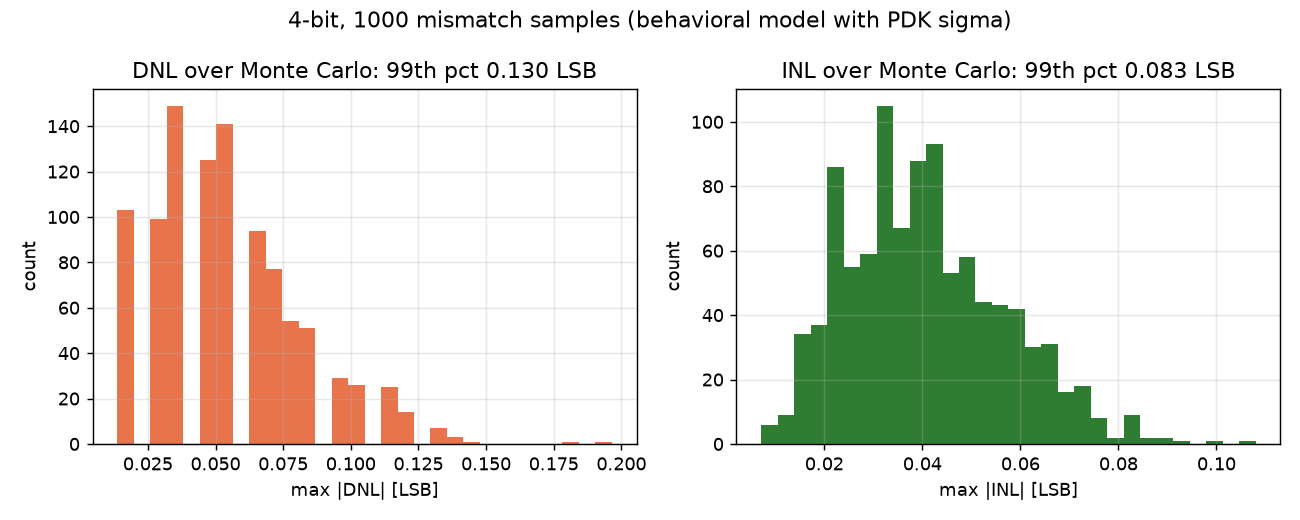

In [10]:
m = res["mc"]
print(f"{m['runs']} runs: 99th percentile DNL {m['dnl_p99']:.3f} LSB, INL {m['inl_p99']:.3f} LSB, "
      f"yield(DNL<0.5 LSB) = {m['yield_dnl_lt_0p5']*100:.1f} %")
Image(filename=str(OUT / "mc_linearity.png"))

## 11. Summary

In [11]:
display(Markdown("## Results" + (OUT / "report.md").read_text().split("## Results")[1]))

## Results (transistor level, pre-layout)
| metric | value |
|---|---|
| ENOB (FFT, 1.016 MHz) | **3.98 bit** (ideal quantizer: 3.97) |
| SNDR / SFDR / THD | 25.72 dB / 35.9 dB / -33.1 dB |
| max DNL / INL (histogram) | 0.031 / 0.021 LSB |
| missing codes | 0 |
| offset / gain error | -0.089 / -0.021 LSB |
| comparator offset sigma (MC, n=192) | 8.00 mV (0.071 LSB) |
| power (analog: comparator + CDAC + switches) | 6.33 uW |
| energy / conversion | 0.633 pJ |
| Walden FoM | 40.1 fJ/conv-step |
| MC (1000 runs) 99th-pct DNL / INL | 0.130 / 0.083 LSB |
| MC yield (max DNL < 0.5 LSB) | 100.0 % |

Runtime: 332 s


## Roadmap
* **Automated layout** with gLayout: common-centroid MIM unit-cap array, StrongARM, binary-scaled switches.
* **DRC / LVS / PEX** (Magic, Netgen, KLayout) and post-layout re-run of sections 6-10 (pre vs. post table).
* **Resolution sweep 4 to 8 bit**: ENOB, power, area and FoM trends; preamplifier when offset demands it.

## References
1. J. L. McCreary and P. R. Gray, "All-MOS charge redistribution analog-to-digital conversion techniques - Part I," IEEE JSSC, 1975.
2. M. J. M. Pelgrom, A. C. J. Duinmaijer, A. P. G. Welbers, "Matching properties of MOS transistors," IEEE JSSC, 1989.
3. B. Razavi, "The StrongARM latch," IEEE Solid-State Circuits Magazine, 2015.
4. SkyWater SKY130 PDK, https://github.com/google/skywater-pdk
5. IIC-OSIC-TOOLS, https://github.com/iic-jku/IIC-OSIC-TOOLS